In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mlabonset import (
    PulseSimulator,
    DLIM,
    DCFD,
    DLED,
    PulseStatistics,
    plot_overlaid_histograms,
    compare_methods
)

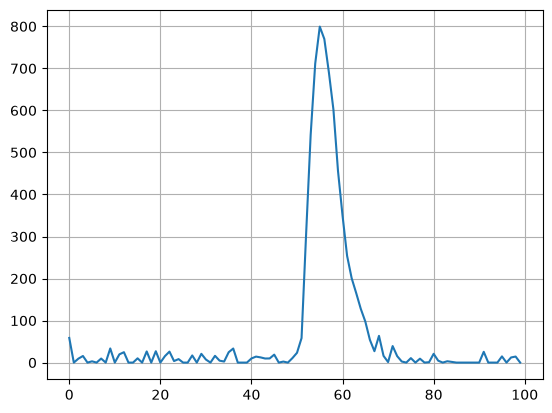

In [ ]:
SAMPLES = 100
pulse_sim = PulseSimulator(SAMPLES)

# Parámetros del pulso
T0_REAL = 50
AMP = 800
TAU = 2
SNR = 50

pulse = pulse_sim.semi_gaussian(t0=T0_REAL, amplitude=AMP, tau=TAU, snr=SNR)

plt.plot(pulse)
plt.grid()
plt.show()

In [24]:
# dataset = pd.DataFrame(
#     pulse_sim.dataset_semigauss(
#         num_pulses=10,
#         t0=T0_REAL,
#         amplitude=[200, 2000, 200],
#         tau=4,
#         snr=[1, 30, 100],
#         offset=50
#     )
# )

# dataset.head()

dataset = pd.DataFrame(
    pulse_sim.generate_dataset(
        model='semi_gaussian',
        num_pulses=10,
        sampling_mode='grid',
    )
)

dataset.head()

,pulse
0,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 56.567493170446..."
1,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 56.567493170446..."
2,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 56.567493170446..."
3,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 56.567493170446..."
4,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 56.567493170446..."


In [25]:
dlimM = DLIM(12)
dcfdM = DCFD(fraction=0.3, delay=2)
dledM = DLED(threshold=120)

In [26]:
stats = PulseStatistics(simulation=True)

results_dlim = stats.evaluate_dataset(
    dataset,
    detect_func=lambda sig: dlimM.t0_get(sig)[1],
    true_t0=T0_REAL
)

results_dlim.head()

,pulse,t0_est,absolute_error,signed_error,normalized_error,valid
0,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 56.567493170446...",5,45,-45,-45,True
1,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 56.567493170446...",5,45,-45,-45,True
2,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 56.567493170446...",5,45,-45,-45,True
3,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 56.567493170446...",5,45,-45,-45,True
4,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 56.567493170446...",5,45,-45,-45,True


In [15]:
agg = stats.aggregated_metrics(
    results_dlim,
    groupby_fields=["tau", "snr"]
)

agg

KeyError: 'tau'

In [27]:
methods = {
    "DLIM": lambda p: dlimM.t0_get(p),
    "DCF": lambda p: dcfdM.t0_get(p),
    "DLED": lambda p: dledM.t0_get(p)
}

compare_df = compare_methods(
    dataset["pulse"].tolist(),
    methods,
    true_t0=T0_REAL,
    simulation=True
)

compare_df.head()

,t0_est,valid,signed_error,absolute_error,method
0,5.0,True,-45.0,45.0,DLIM
1,5.0,True,-45.0,45.0,DLIM
2,5.0,True,-45.0,45.0,DLIM
3,5.0,True,-45.0,45.0,DLIM
4,5.0,True,-45.0,45.0,DLIM


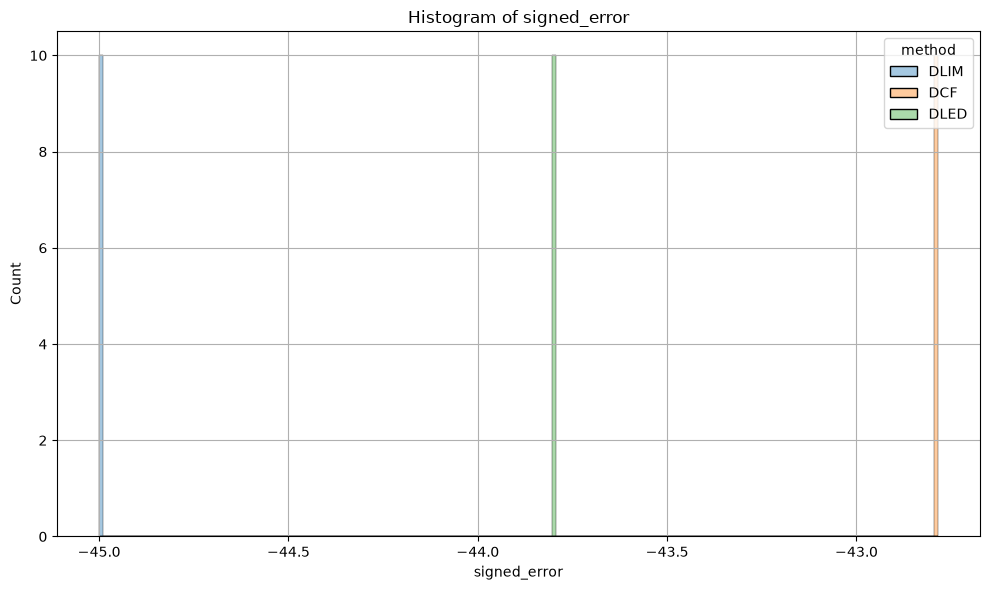

In [17]:
plot_overlaid_histograms(
    df=compare_df,
    column="signed_error",
    hue="method",
    bins=200,
)

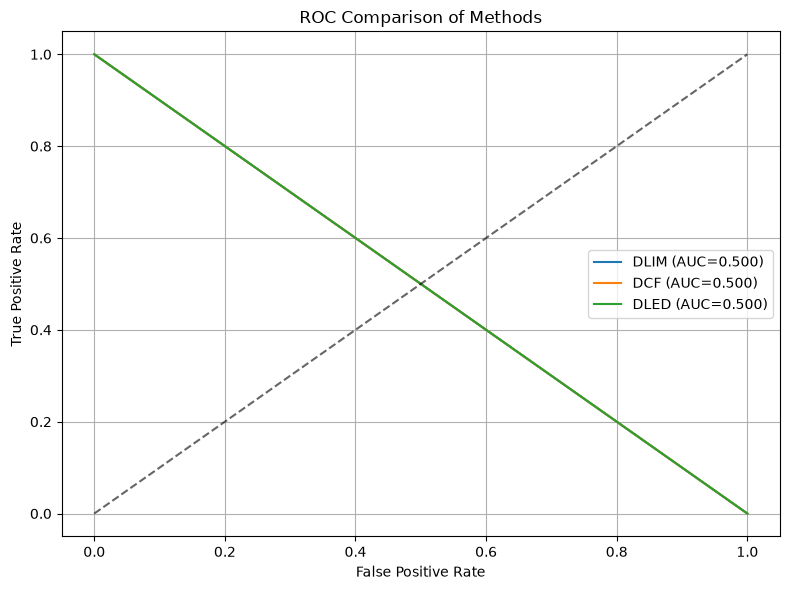

In [28]:
thresholds = np.linspace(0.1, 50, 500)

roc_dlim = stats.compute_roc_auc(compare_df[compare_df["method"]=="DLIM"], T0_REAL, thresholds)
roc_dcf  = stats.compute_roc_auc(compare_df[compare_df["method"]=="DCF"], T0_REAL, thresholds)
roc_dled = stats.compute_roc_auc(compare_df[compare_df["method"]=="DLED"], T0_REAL, thresholds)

PulseStatistics.plot_multi_roc({
    "DLIM": roc_dlim,
    "DCF": roc_dcf,
    "DLED": roc_dled
})